---
title: "Practice Activity 9-2: Model Error, Cross-Validation, Pipelines"
author: "Shiqi Wu"
format:
  html:
    embed-resources: true
    code-overflow: wrap
---

# Training and Test Errors, Cross-Validation, Pipelines

In [1]:
import pandas as pd
import numpy as np

from plotnine import *

**Use scikit-learn, including pipelines, whenever possible.**

## Ames Housing Data


We have fit different regression models to predict house prices (SalePrice, not log). Now we will evaluate models by estimating their prediction error.

In [2]:
df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep = "\t")

df_ames

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


Since all of the houses in the data set have a SalePrice, we'll include all the observations in the training data. We'll start with a basic linear regression model with a few features.

In [3]:
X_train = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]]

y_train = df_ames["SalePrice"]

In [4]:
from sklearn.linear_model import LinearRegression

model1 = LinearRegression()
model1.fit(
    X=X_train,
    y=y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


1. Explain conceptually what the "fit" step does. What is the output?

Answer: The fit step uses the training features and known sale prices to learn the intercept and coefficients of the linear regression model. It chooses these values to minimize the sum of squared errors between the actual and predicted training prices. The output is a fitted model that can be used to predict sale prices, rather than the predictions themselves.

2. Explain conceptually how you would compute the *training* RMSE (root mean square error) of this model.

Answer: First, use the fitted model to predict sale prices for the training houses using X_train. Subtract each predicted price from its actual SalePrice, square each error, and take the mean of the squared errors. Finally, take the square root of this mean to obtain the training RMSE, which is measured in dollars.

3. Interpret the *training RMSE*. Is it big or small? What could you use as a rough benchmark for comparison?

In [5]:
from sklearn.metrics import mean_squared_error

train_predictions = model1.predict(X_train)

train_rmse = np.sqrt(
    mean_squared_error(y_train, train_predictions)
)

train_rmse

np.float64(51350.41833606974)

In [6]:
mean_price = y_train.mean()

baseline_rmse = np.sqrt(
    ((y_train - mean_price) ** 2).mean()
)

baseline_rmse

np.float64(79873.05865192253)

Answer: The training RMSE is about 51350.42 dollars, which measures the size of the model's prediction errors on the training houses. Whether this is large or small depends on the context. A rough benchmark is a model that predicts the mean training sale price for every house, which has a training RMSE of about 79873.06 dollars. Our model has a lower training RMSE, so it performs better than this simple benchmark on the training data, but this does not tell us how well it will predict new houses.

4. Suppose we add more features like "TotRms AbvGrd" and fit a new model. Would the *training* RMSE increase or decrease? Why is comparing the *training* RMSE of these two models not useful?

Answer: Adding more features to the linear regression model will decrease the training RMSE or leave it unchanged. The new model can reproduce the original model by setting the added coefficients to zero, so its training RMSE cannot be higher when fitted to the same data. However, a lower training RMSE does not necessarily mean better predictions for new houses, because the model may overfit the training data. We should compare the models using validation or cross-validation error instead.

5. If we fit a 1-nearest neighbor model, what should the *training* RMSE be?

Answer: The training RMSE should be 0 when each training house is its own nearest neighbor. The model then predicts each house's actual sale price, so all training errors are zero. This assumes there are no identical feature combinations with different sale prices. A zero training RMSE does not guarantee accurate predictions for new houses.

6. What happens to the *training* RMSE of a $k$-nearest neighbors model as $k$ increases?

Answer: As k increases, the training RMSE generally tends to increase because predictions average the sale prices of more neighbors instead of closely matching each training house's own price. The model becomes smoother and usually fits the training data less closely. However, the training RMSE is not guaranteed to increase at every step.

7. We are really interested in the *test* RMSE, not the *training* RMSE. Explain why in practice you can not compute the *test* RMSE.

Answer: In practice, the actual sale prices of the new houses we want to predict are not yet known. Without these true values, we cannot calculate their prediction errors or the test RMSE directly. We can instead use a held-out labeled data set or cross-validation to estimate how well the model will predict new houses.

8. Explain conceptually how cross-validations *estimates* the *test* RMSE.

Answer: Cross-validation divides the labeled data into several folds. For each round, the model is fitted on all but one fold and evaluated on the remaining fold, whose actual sale prices are known. Each fold takes a turn as the validation set. We calculate the RMSE for each fold and average these values to estimate prediction error on new houses. Any preprocessing must also be fitted using only the training folds in each round.

9. We'll use cross-validation to estimate the *test* RMSE for the model from part 1. Will the *test* RMSE be greater than, less than, or equal to the *training* RMSE for this model?

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

base_features = [
    "Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"
]

X_base = df_ames[base_features]
y_housing = df_ames["SalePrice"]

base_pipeline = Pipeline([
    ("lm", LinearRegression())
])

base_scores = cross_val_score(
    base_pipeline,
    X_base,
    y_housing,
    scoring="neg_mean_squared_error",
    cv=10
)

base_cv_rmse = np.sqrt(-base_scores).mean()

print("Training RMSE:", train_rmse)
print("Cross-validation RMSE:", base_cv_rmse)

Training RMSE: 51350.41833606974
Cross-validation RMSE: 51455.31785329247


Answer: The estimated test RMSE from 10-fold cross-validation is about 51455.32 dollars, which is slightly higher than the training RMSE of 51350.42 dollars. This is expected because cross-validation evaluates predictions on houses that were not used to fit the model in that fold, while training RMSE evaluates houses used to fit the model.

10. Suppose we add features like we did in part 4. Will the *test* RMSE necessarily decrease? Fit the test RMSE and compare the two models - which is better based on this criteria?

In [8]:
extended_features = base_features + ["TotRms AbvGrd"]
X_extended = df_ames[extended_features]

extended_pipeline = Pipeline([
    ("lm", LinearRegression())
])

extended_scores = cross_val_score(
    extended_pipeline,
    X_extended,
    y_housing,
    scoring="neg_mean_squared_error",
    cv=10
)

extended_cv_rmse = np.sqrt(-extended_scores).mean()

print("Original model CV RMSE:", base_cv_rmse)
print("Added-feature model CV RMSE:", extended_cv_rmse)

Original model CV RMSE: 51455.31785329247
Added-feature model CV RMSE: 51574.93326498653


Answer: Adding more features does not necessarily decrease the test RMSE. After adding TotRms AbvGrd, the estimated test RMSE from 10-fold cross-validation increases from about 51455.32 to 51574.93 dollars. The original model performs slightly better in this comparison because it has the lower cross-validated RMSE.

11. Now suppose we add a categorical predictor like Neighborhood. The crossval code below will (probably) error. Explain why. Hint: think about how the cross-validation process works and how categorical variables are treated.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

ct = ColumnTransformer(
    [("standardize", StandardScaler(), ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"],),
     ("dummify", OneHotEncoder(), ["Neighborhood"]),
    ],
    remainder="drop",
)

neighborhood_model = Pipeline(
    [("preprocessing", ct),
     ("lm", LinearRegression())]
)

X_train = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "Neighborhood"]]
y_train = df_ames["SalePrice"]

neighborhood_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('lm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardize', ...), ('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different trans

In [12]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(neighborhood_model,
                         X = X_train,
                         y = y_train,
                         scoring="neg_mean_squared_error",
                         cv=10)
scores

/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/model_selection/_validation.py:945: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/metrics/_scorer.py", line 166, in __call__
    score = scorer._score(
            ^^^^^^^^^^^^^^
  File "/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/metrics/_scorer.py", line 409, in _score
    y_pred = method_caller(
             ^^^^^^^^^^^^^^
  File "/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/metrics/_scorer.py", line 96, in _cached_call
    result, _ = _get_response_values(
                ^^^^^^^^^^^^^^^^^^^^^
  File "/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/utils/_response.py", line 242, in _get_response_values
    y_pred, pos_label 

array([-1.44545960e+09, -2.17595046e+09, -1.03959067e+09, -1.75337711e+09,
       -1.09461091e+09, -2.46145139e+09, -1.41979799e+09, -2.32075542e+09,
       -1.21633488e+09,             nan])

Answer: During cross-validation, the pipeline is refitted using only the training portion of each fold. A neighborhood may appear in the validation portion but not in that fold's training portion. In this run, Landmrk is an unseen category. The default OneHotEncoder cannot transform unseen categories, so scoring fails for that fold and its score becomes nan. Fitting the pipeline on the full data beforehand does not prevent this because cross-validation refits it separately in each fold.

11. Going back to part 1, suppose we had standardized the features first. Would the coeffiecients of the fitted model change? Would the *training* RMSE change?

Answer: Standardizing the features generally changes the fitted coefficients because the features are measured on a different scale. However, for this linear regression model with an intercept and no regularization, the training predictions and training RMSE remain the same, apart from small numerical differences. Standardization changes how the model is expressed, not its fit to the training data.

12. Suppose we want to standardize predictors like in the previous part and estimate test RMSE using cross-validation. Explain how standardization fits in in the CV process. Also explain why it is important to put standardization as part of the model pipeline.

Answer: In each cross-validation round, the scaler should learn the feature means and standard deviations using only that fold's training portion. These same values are then used to transform both the training and validation portions before fitting and evaluating the model. Including standardization in the pipeline ensures that this process is repeated correctly in every fold and prevents information from the validation portion from leaking into training.

## Practice Activity

We'll continue with the housing data and our goal of predicting Sale Price.

We will have a competition to see who can come up with the model with the smallest *test* RMSE. Fit several models and try to find the smallest *test* RMSE. Use cross-validation to estimate the *test* RMSE. When you think you have a good model, share your it and its test RMSE with a partner. Then see what other people have done; can you do even better?

Note: next week we will see how to make some of these choices in a more automated way. For now just work by trial and error. You should try:

- Exploring the data first! Make some plots and summaries to get an idea of what might be good predictors to try
- Several different sets of predictors, including both categorical and numerical predictors
- Linear regression models, including models with polynomial features and interactions
- K-nearest neighbors models, inclduing different values of k
- Decision trees, including different sizes of trees

Use pipelines as much as possible, and don't forget to transform variables as needed.

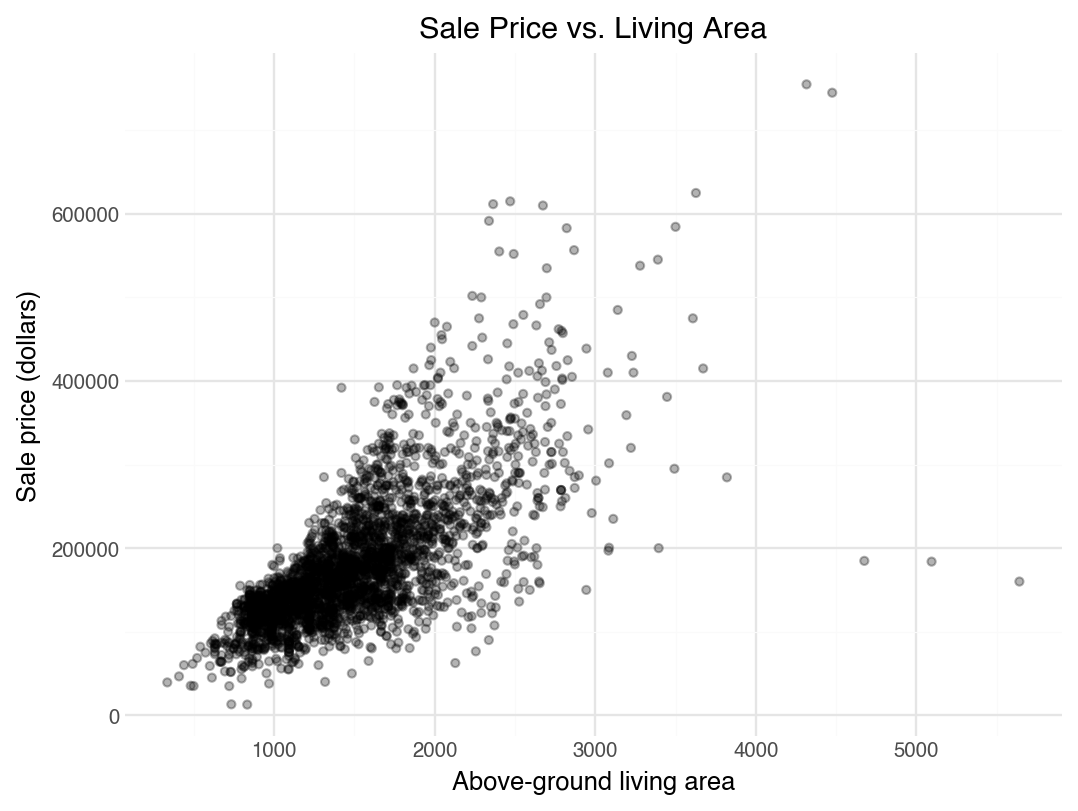

In [13]:
(
    ggplot(df_ames, aes(x="Gr Liv Area", y="SalePrice"))
    + geom_point(alpha=0.3)
    + labs(
        x="Above-ground living area",
        y="Sale price (dollars)",
        title="Sale Price vs. Living Area"
    )
    + theme_minimal()
)

In [14]:
numeric_candidates = [
    "Gr Liv Area", "Overall Qual", "Year Built"
]

df_ames[["SalePrice"] + numeric_candidates].corr()["SalePrice"]

SalePrice       1.000000
Gr Liv Area     0.706780
Overall Qual    0.799262
Year Built      0.558426
Name: SalePrice, dtype: float64

In [15]:
activity_numeric = numeric_candidates
activity_features = activity_numeric + ["Neighborhood"]

X_activity = df_ames[activity_features]
y_activity = df_ames["SalePrice"]

activity_preprocessing = ColumnTransformer([
    ("standardize", StandardScaler(), activity_numeric),
    ("dummify", OneHotEncoder(handle_unknown="ignore"),
     ["Neighborhood"])
])

activity_linear = Pipeline([
    ("preprocessing", activity_preprocessing),
    ("lm", LinearRegression())
])

activity_linear_scores = cross_val_score(
    activity_linear,
    X_activity,
    y_activity,
    scoring="neg_mean_squared_error",
    cv=10
)

activity_linear_rmse = np.sqrt(-activity_linear_scores).mean()
activity_linear_rmse

np.float64(35453.470778933486)

In [16]:
from sklearn.preprocessing import PolynomialFeatures

polynomial_preprocessing = ColumnTransformer([
    ("numeric", Pipeline([
        ("standardize", StandardScaler()),
        ("polynomial", PolynomialFeatures(
            degree=2, include_bias=False
        ))
    ]), activity_numeric),
    ("dummify", OneHotEncoder(handle_unknown="ignore"),
     ["Neighborhood"])
])

activity_polynomial = Pipeline([
    ("preprocessing", polynomial_preprocessing),
    ("lm", LinearRegression())
])

activity_polynomial_scores = cross_val_score(
    activity_polynomial,
    X_activity,
    y_activity,
    scoring="neg_mean_squared_error",
    cv=10
)

activity_polynomial_rmse = np.sqrt(
    -activity_polynomial_scores
).mean()

activity_polynomial_rmse

np.float64(33804.15186370131)

In [17]:
from sklearn.neighbors import KNeighborsRegressor

activity_knn5 = Pipeline([
    ("preprocessing", activity_preprocessing),
    ("knn", KNeighborsRegressor(n_neighbors=5))
])

activity_knn5_scores = cross_val_score(
    activity_knn5,
    X_activity,
    y_activity,
    scoring="neg_mean_squared_error",
    cv=10
)

activity_knn5_rmse = np.sqrt(-activity_knn5_scores).mean()
activity_knn5_rmse

np.float64(33757.62525443362)

In [18]:
activity_knn10 = Pipeline([
    ("preprocessing", activity_preprocessing),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

activity_knn10_scores = cross_val_score(
    activity_knn10,
    X_activity,
    y_activity,
    scoring="neg_mean_squared_error",
    cv=10
)

activity_knn10_rmse = np.sqrt(-activity_knn10_scores).mean()


activity_knn20 = Pipeline([
    ("preprocessing", activity_preprocessing),
    ("knn", KNeighborsRegressor(n_neighbors=20))
])

activity_knn20_scores = cross_val_score(
    activity_knn20,
    X_activity,
    y_activity,
    scoring="neg_mean_squared_error",
    cv=10
)

activity_knn20_rmse = np.sqrt(-activity_knn20_scores).mean()

print("k=5 CV RMSE:", activity_knn5_rmse)
print("k=10 CV RMSE:", activity_knn10_rmse)
print("k=20 CV RMSE:", activity_knn20_rmse)

k=5 CV RMSE: 33757.62525443362
k=10 CV RMSE: 33191.22649165415
k=20 CV RMSE: 33565.71671766145


In [19]:
from sklearn.tree import DecisionTreeRegressor

activity_tree_preprocessing = ColumnTransformer([
    ("numeric", "passthrough", activity_numeric),
    ("dummify", OneHotEncoder(handle_unknown="ignore"),
     ["Neighborhood"])
])

activity_tree4 = Pipeline([
    ("preprocessing", activity_tree_preprocessing),
    ("tree", DecisionTreeRegressor(
        max_depth=4, random_state=42
    ))
])

activity_tree4_scores = cross_val_score(
    activity_tree4,
    X_activity,
    y_activity,
    scoring="neg_mean_squared_error",
    cv=10
)

activity_tree4_rmse = np.sqrt(-activity_tree4_scores).mean()
activity_tree4_rmse

np.float64(40018.38988676481)

In [20]:
activity_tree6 = Pipeline([
    ("preprocessing", activity_tree_preprocessing),
    ("tree", DecisionTreeRegressor(
        max_depth=6, random_state=42
    ))
])

activity_tree6_scores = cross_val_score(
    activity_tree6,
    X_activity,
    y_activity,
    scoring="neg_mean_squared_error",
    cv=10
)

activity_tree6_rmse = np.sqrt(-activity_tree6_scores).mean()


activity_tree8 = Pipeline([
    ("preprocessing", activity_tree_preprocessing),
    ("tree", DecisionTreeRegressor(
        max_depth=8, random_state=42
    ))
])

activity_tree8_scores = cross_val_score(
    activity_tree8,
    X_activity,
    y_activity,
    scoring="neg_mean_squared_error",
    cv=10
)

activity_tree8_rmse = np.sqrt(-activity_tree8_scores).mean()

print("Depth 4 CV RMSE:", activity_tree4_rmse)
print("Depth 6 CV RMSE:", activity_tree6_rmse)
print("Depth 8 CV RMSE:", activity_tree8_rmse)

Depth 4 CV RMSE: 40018.38988676481
Depth 6 CV RMSE: 36590.10907333483
Depth 8 CV RMSE: 34124.52592332327


In [21]:
from sklearn.base import clone

best_model = clone(activity_knn10)
best_model.fit(X_activity, y_activity)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardize', ...), ('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tran

Answer: I explored the data and compared linear regression, quadratic regression with interaction terms, KNN models with k values of 5, 10, and 20, and decision trees with maximum depths of 4, 6, and 8. All models were evaluated using the same 10-fold cross-validation procedure. Among the models tested, KNN with k=10 had the lowest estimated test RMSE of about 33191.23 dollars. It uses Gr Liv Area, Overall Qual, Year Built, and Neighborhood, with numerical features standardized and Neighborhood one-hot encoded within the pipeline. I selected this model and fitted it on all available observations. This was the best result among the models tried, not a guarantee that no other model could perform better.